# Baryonic Validation 4: Outer Gap Diagnostic — Corrected FAIR² Reproduction
**Flynn (2026), 84-Galaxy Baryonic Validation (Flynn 2026)**

The outer gap Vadj(R2) − Vbary(R2) is negative for ALL 84 galaxies.
Archived Paper 2 mean = −51.4 ± 25.0 km/s; the corrected FAIR² value is recomputed below.

**Interpretation:** This outer-boundary residual is a consistency diagnostic.
Because the correction is derived from boundary kinematics, the negative sign
should not be treated as an independent exclusion of a dark-matter halo model.

In [1]:
# ── Colab setup: download SPARC corpus from Zenodo ────────────
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    import urllib.request
    url = 'https://zenodo.org/records/19563417/files/rotation_curve_corpus_v7.json'
    if not os.path.exists('rotation_curve_corpus_v7.json'):
        print("Downloading SPARC corpus...")
        urllib.request.urlretrieve(url, 'rotation_curve_corpus_v7.json')
        print("  ✓ rotation_curve_corpus_v7.json")
    print("Ready.")
else:
    print("Running locally.")


Running locally.


In [2]:
# Paper 2 published results — Flynn (2026), 84-Galaxy Baryonic Validation (Flynn 2026)
# Embedded directly from Table 2. DOI: 10.5281/zenodo.19798527
import json, numpy as np
import matplotlib.pyplot as plt

P2_DATA = [{"galaxy": "NGC3741", "omega": 7.032, "upsilon": 1.0, "rmse_kepler": 14.55, "rmse_bary": 5.3, "rmse_bary_kepler": 12.81}, {"galaxy": "UGC08550", "omega": 9.317, "upsilon": 1.0, "rmse_kepler": 20.37, "rmse_bary": 8.77, "rmse_bary_kepler": 22.76}, {"galaxy": "NGC3109", "omega": 10.244, "upsilon": 1.0, "rmse_kepler": 12.11, "rmse_bary": 8.08, "rmse_bary_kepler": 19.27}, {"galaxy": "UGC07603", "omega": 14.2, "upsilon": 0.94, "rmse_kepler": 20.42, "rmse_bary": 8.27, "rmse_bary_kepler": 26.99}, {"galaxy": "DDO064", "omega": 15.35, "upsilon": 1.0, "rmse_kepler": 11.86, "rmse_bary": 8.49, "rmse_bary_kepler": 18.23}, {"galaxy": "UGC01281", "omega": 11.37, "upsilon": 1.0, "rmse_kepler": 10.72, "rmse_bary": 7.35, "rmse_bary_kepler": 16.45}, {"galaxy": "UGC07151", "omega": 12.53, "upsilon": 0.953, "rmse_kepler": 27.53, "rmse_bary": 16.09, "rmse_bary_kepler": 38.72}, {"galaxy": "UGC07399", "omega": 14.86, "upsilon": 1.0, "rmse_kepler": 14.39, "rmse_bary": 14.38, "rmse_bary_kepler": 22.1}, {"galaxy": "UGC04278", "omega": 13.76, "upsilon": 1.0, "rmse_kepler": 28.3, "rmse_bary": 16.5, "rmse_bary_kepler": 39.88}, {"galaxy": "NGC3972", "omega": 13.93, "upsilon": 0.675, "rmse_kepler": 43.21, "rmse_bary": 20.03, "rmse_bary_kepler": 57.13}, {"galaxy": "NGC7793", "omega": 11.4, "upsilon": 0.111, "rmse_kepler": 25.07, "rmse_bary": 25.07, "rmse_bary_kepler": 37.62}, {"galaxy": "F571-8", "omega": 9.17, "upsilon": 0.104, "rmse_kepler": 20.97, "rmse_bary": 20.97, "rmse_bary_kepler": 31.46}, {"galaxy": "UGC05721", "omega": 11.51, "upsilon": 0.979, "rmse_kepler": 14.46, "rmse_bary": 14.46, "rmse_bary_kepler": 21.69}, {"galaxy": "UGC07323", "omega": 13.41, "upsilon": 0.986, "rmse_kepler": 39.27, "rmse_bary": 13.42, "rmse_bary_kepler": 55.2}, {"galaxy": "NGC3521", "omega": 10.25, "upsilon": 0.535, "rmse_kepler": 33.3, "rmse_bary": 23.06, "rmse_bary_kepler": 45.32}, {"galaxy": "F563-V2", "omega": 11.08, "upsilon": 1.0, "rmse_kepler": 30.87, "rmse_bary": 30.28, "rmse_bary_kepler": 46.31}, {"galaxy": "ESO116-G012", "omega": 11.02, "upsilon": 1.0, "rmse_kepler": 29.42, "rmse_bary": 18.61, "rmse_bary_kepler": 44.13}, {"galaxy": "F568-1", "omega": 10.52, "upsilon": 1.0, "rmse_kepler": 27.53, "rmse_bary": 26.67, "rmse_bary_kepler": 41.3}, {"galaxy": "ESO079-G014", "omega": 10.37, "upsilon": 0.742, "rmse_kepler": 53.87, "rmse_bary": 26.33, "rmse_bary_kepler": 73.28}, {"galaxy": "NGC3893", "omega": 6.47, "upsilon": 0.507, "rmse_kepler": 23.82, "rmse_bary": 21.27, "rmse_bary_kepler": 32.73}, {"galaxy": "UGC08286", "omega": 9.82, "upsilon": 1.0, "rmse_kepler": 16.95, "rmse_bary": 16.14, "rmse_bary_kepler": 23.97}, {"galaxy": "NGC0024", "omega": 9.55, "upsilon": 0.873, "rmse_kepler": 18.54, "rmse_bary": 18.54, "rmse_bary_kepler": 25.74}, {"galaxy": "NGC0100", "omega": 9.37, "upsilon": 0.504, "rmse_kepler": 18.46, "rmse_bary": 13.41, "rmse_bary_kepler": 26.17}, {"galaxy": "NGC0891", "omega": 8.99, "upsilon": 0.326, "rmse_kepler": 35.78, "rmse_bary": 31.41, "rmse_bary_kepler": 50.75}, {"galaxy": "NGC4217", "omega": 9.99, "upsilon": 0.1, "rmse_kepler": 31.09, "rmse_bary": 31.09, "rmse_bary_kepler": 44.04}, {"galaxy": "UGC06917", "omega": 8.3, "upsilon": 1.0, "rmse_kepler": 27.12, "rmse_bary": 15.44, "rmse_bary_kepler": 38.4}, {"galaxy": "NGC7814", "omega": 8.52, "upsilon": 0.582, "rmse_kepler": 26.55, "rmse_bary": 23.98, "rmse_bary_kepler": 37.61}, {"galaxy": "NGC3917", "omega": 8.82, "upsilon": 0.465, "rmse_kepler": 32.71, "rmse_bary": 24.89, "rmse_bary_kepler": 46.3}, {"galaxy": "F583-4", "omega": 9.33, "upsilon": 1.0, "rmse_kepler": 25.77, "rmse_bary": 11.29, "rmse_bary_kepler": 36.5}, {"galaxy": "IC4202", "omega": 9.3, "upsilon": 0.1, "rmse_kepler": 60.24, "rmse_bary": 60.24, "rmse_bary_kepler": 85.32}, {"galaxy": "UGC08490", "omega": 6.95, "upsilon": 1.0, "rmse_kepler": 11.8, "rmse_bary": 11.8, "rmse_bary_kepler": 16.72}, {"galaxy": "NGC4088", "omega": 6.98, "upsilon": 0.383, "rmse_kepler": 56.43, "rmse_bary": 33.12, "rmse_bary_kepler": 79.91}, {"galaxy": "NGC6946", "omega": 6.83, "upsilon": 0.426, "rmse_kepler": 35.22, "rmse_bary": 29.6, "rmse_bary_kepler": 49.91}, {"galaxy": "F568-3", "omega": 6.54, "upsilon": 0.829, "rmse_kepler": 24.46, "rmse_bary": 22.04, "rmse_bary_kepler": 34.65}, {"galaxy": "F568-V1", "omega": 6.55, "upsilon": 1.0, "rmse_kepler": 23.0, "rmse_bary": 23.0, "rmse_bary_kepler": 32.58}, {"galaxy": "NGC2403", "omega": 6.32, "upsilon": 0.84, "rmse_kepler": 21.59, "rmse_bary": 18.47, "rmse_bary_kepler": 30.57}, {"galaxy": "UGC12632", "omega": 6.27, "upsilon": 1.0, "rmse_kepler": 17.02, "rmse_bary": 15.48, "rmse_bary_kepler": 24.11}, {"galaxy": "UGC11455", "omega": 6.24, "upsilon": 0.243, "rmse_kepler": 48.59, "rmse_bary": 48.59, "rmse_bary_kepler": 68.81}, {"galaxy": "NGC5985", "omega": 6.16, "upsilon": 1.0, "rmse_kepler": 55.76, "rmse_bary": 50.73, "rmse_bary_kepler": 78.95}, {"galaxy": "UGC00731", "omega": 5.99, "upsilon": 1.0, "rmse_kepler": 17.5, "rmse_bary": 17.5, "rmse_bary_kepler": 24.78}, {"galaxy": "UGC06786", "omega": 5.87, "upsilon": 0.736, "rmse_kepler": 23.73, "rmse_bary": 23.73, "rmse_bary_kepler": 33.6}, {"galaxy": "NGC6195", "omega": 5.83, "upsilon": 0.52, "rmse_kepler": 64.55, "rmse_bary": 48.4, "rmse_bary_kepler": 91.41}, {"galaxy": "UGC12732", "omega": 5.81, "upsilon": 1.0, "rmse_kepler": 20.66, "rmse_bary": 20.03, "rmse_bary_kepler": 29.26}, {"galaxy": "NGC4157", "omega": 5.46, "upsilon": 0.423, "rmse_kepler": 39.98, "rmse_bary": 30.12, "rmse_bary_kepler": 56.63}, {"galaxy": "UGC06930", "omega": 5.44, "upsilon": 1.0, "rmse_kepler": 29.91, "rmse_bary": 21.94, "rmse_bary_kepler": 42.36}, {"galaxy": "UGC03205", "omega": 5.27, "upsilon": 0.65, "rmse_kepler": 33.88, "rmse_bary": 33.83, "rmse_bary_kepler": 47.98}, {"galaxy": "UGC11820", "omega": 5.21, "upsilon": 1.0, "rmse_kepler": 18.05, "rmse_bary": 18.01, "rmse_bary_kepler": 25.56}, {"galaxy": "NGC4100", "omega": 5.2, "upsilon": 0.867, "rmse_kepler": 39.64, "rmse_bary": 23.68, "rmse_bary_kepler": 56.13}, {"galaxy": "UGC03546", "omega": 5.29, "upsilon": 0.433, "rmse_kepler": 16.43, "rmse_bary": 16.43, "rmse_bary_kepler": 23.28}, {"galaxy": "F563-1", "omega": 5.02, "upsilon": 1.0, "rmse_kepler": 22.03, "rmse_bary": 22.03, "rmse_bary_kepler": 31.21}, {"galaxy": "NGC4559", "omega": 5.3, "upsilon": 0.551, "rmse_kepler": 30.57, "rmse_bary": 24.26, "rmse_bary_kepler": 43.29}, {"galaxy": "F583-1", "omega": 5.16, "upsilon": 0.677, "rmse_kepler": 17.14, "rmse_bary": 17.14, "rmse_bary_kepler": 24.27}, {"galaxy": "NGC2955", "omega": 5.71, "upsilon": 0.564, "rmse_kepler": 53.77, "rmse_bary": 44.29, "rmse_bary_kepler": 76.14}, {"galaxy": "NGC7331", "omega": 4.9, "upsilon": 0.409, "rmse_kepler": 34.27, "rmse_bary": 25.73, "rmse_bary_kepler": 48.53}, {"galaxy": "NGC4183", "omega": 4.92, "upsilon": 1.0, "rmse_kepler": 30.0, "rmse_bary": 22.98, "rmse_bary_kepler": 42.49}, {"galaxy": "DDO161", "omega": 4.69, "upsilon": 1.0, "rmse_kepler": 15.32, "rmse_bary": 12.01, "rmse_bary_kepler": 21.7}, {"galaxy": "NGC6503", "omega": 4.3, "upsilon": 0.59, "rmse_kepler": 15.25, "rmse_bary": 15.25, "rmse_bary_kepler": 21.59}, {"galaxy": "NGC2998", "omega": 4.61, "upsilon": 0.859, "rmse_kepler": 67.46, "rmse_bary": 54.82, "rmse_bary_kepler": 95.55}, {"galaxy": "NGC1090", "omega": 5.24, "upsilon": 0.184, "rmse_kepler": 39.21, "rmse_bary": 39.21, "rmse_bary_kepler": 55.52}, {"galaxy": "NGC5033", "omega": 3.79, "upsilon": 0.49, "rmse_kepler": 31.58, "rmse_bary": 31.58, "rmse_bary_kepler": 44.73}, {"galaxy": "NGC5371", "omega": 3.78, "upsilon": 0.617, "rmse_kepler": 75.88, "rmse_bary": 53.05, "rmse_bary_kepler": 107.44}, {"galaxy": "F579-V1", "omega": 7.13, "upsilon": 1.0, "rmse_kepler": 31.66, "rmse_bary": 29.14, "rmse_bary_kepler": 44.84}, {"galaxy": "UGC06983", "omega": 5.74, "upsilon": 0.978, "rmse_kepler": 19.52, "rmse_bary": 18.58, "rmse_bary_kepler": 27.66}, {"galaxy": "NGC2841", "omega": 3.58, "upsilon": 0.966, "rmse_kepler": 26.69, "rmse_bary": 26.69, "rmse_bary_kepler": 37.79}, {"galaxy": "UGC05750", "omega": 3.44, "upsilon": 0.525, "rmse_kepler": 14.01, "rmse_bary": 14.01, "rmse_bary_kepler": 19.84}, {"galaxy": "UGC05005", "omega": 3.38, "upsilon": 0.806, "rmse_kepler": 16.97, "rmse_bary": 15.72, "rmse_bary_kepler": 24.03}, {"galaxy": "UGC02885", "omega": 3.4, "upsilon": 0.823, "rmse_kepler": 72.32, "rmse_bary": 53.94, "rmse_bary_kepler": 102.36}, {"galaxy": "NGC5055", "omega": 2.89, "upsilon": 0.385, "rmse_kepler": 25.49, "rmse_bary": 25.49, "rmse_bary_kepler": 36.09}, {"galaxy": "NGC6674", "omega": 2.81, "upsilon": 0.953, "rmse_kepler": 46.7, "rmse_bary": 40.82, "rmse_bary_kepler": 66.13}, {"galaxy": "UGC01230", "omega": 2.74, "upsilon": 0.863, "rmse_kepler": 29.3, "rmse_bary": 29.3, "rmse_bary_kepler": 41.49}, {"galaxy": "UGC06614", "omega": 2.49, "upsilon": 0.597, "rmse_kepler": 16.76, "rmse_bary": 16.28, "rmse_bary_kepler": 23.74}, {"galaxy": "UGC02487", "omega": 2.49, "upsilon": 1.0, "rmse_kepler": 23.1, "rmse_bary": 23.1, "rmse_bary_kepler": 32.72}, {"galaxy": "UGC00128", "omega": 2.23, "upsilon": 1.0, "rmse_kepler": 23.16, "rmse_bary": 23.16, "rmse_bary_kepler": 32.79}, {"galaxy": "NGC0801", "omega": 3.32, "upsilon": 0.448, "rmse_kepler": 54.24, "rmse_bary": 52.86, "rmse_bary_kepler": 76.8}, {"galaxy": "UGC09133", "omega": 1.97, "upsilon": 0.66, "rmse_kepler": 32.6, "rmse_bary": 32.6, "rmse_bary_kepler": 46.18}, {"galaxy": "UGC07125", "omega": 3.09, "upsilon": 0.787, "rmse_kepler": 20.09, "rmse_bary": 16.69, "rmse_bary_kepler": 28.45}, {"galaxy": "NGC1003", "omega": 3.49, "upsilon": 0.679, "rmse_kepler": 14.38, "rmse_bary": 14.12, "rmse_bary_kepler": 20.36}, {"galaxy": "NGC3198", "omega": 3.33, "upsilon": 0.149, "rmse_kepler": 47.07, "rmse_bary": 47.08, "rmse_bary_kepler": 66.65}, {"galaxy": "NGC2903", "omega": 7.01, "upsilon": 0.1, "rmse_kepler": 61.98, "rmse_bary": 61.98, "rmse_bary_kepler": 87.75}, {"galaxy": "ESO563-G021", "omega": 7.31, "upsilon": 0.1, "rmse_kepler": 82.04, "rmse_bary": 82.04, "rmse_bary_kepler": 116.13}, {"galaxy": "NGC5585", "omega": 8.06, "upsilon": 0.6, "rmse_kepler": 16.52, "rmse_bary": 13.89, "rmse_bary_kepler": 23.39}, {"galaxy": "F574-1", "omega": 7.68, "upsilon": 1.0, "rmse_kepler": 27.16, "rmse_bary": 20.38, "rmse_bary_kepler": 38.46}, {"galaxy": "UGC06446", "omega": 7.11, "upsilon": 1.0, "rmse_kepler": 15.36, "rmse_bary": 15.36, "rmse_bary_kepler": 21.75}, {'galaxy': 'UGC07524', 'omega': 7.15, 'upsilon': 0.87, 'rmse_kepler': 20.78, 'rmse_bary': 16.1, 'rmse_bary_kepler': None}]
print(f"Paper 2 dataset: {len(P2_DATA)} galaxies")
omegas = [d['omega'] for d in P2_DATA]
rmses  = [d['rmse_bary'] for d in P2_DATA]
print(f"Mean omega:  {np.mean(omegas):.2f} ± {np.std(omegas):.2f} rad/Gyr")
print(f"Mean RMSE:   {np.mean(rmses):.2f} km/s")
print(f"Published:   7.06 ± 3.26 rad/Gyr, 25.45 km/s (Flynn 2026)")


Paper 2 dataset: 84 galaxies
Mean omega:  7.06 ± 3.24 rad/Gyr
Mean RMSE:   25.45 km/s
Published:   7.06 ± 3.26 rad/Gyr, 25.45 km/s (Flynn 2026)


In [3]:
import os
# Load corpus to compute outer gap
import json
with open(os.path.expanduser('../hi/rotation_curve_corpus_v7.json')) as f:
    corpus = json.load(f)
galaxies = {g['galaxy']: g for g in corpus['galaxies'] if g.get('survey') == 'SPARC'}

# Build P2 lookup
p2_lookup = {d['galaxy']: d for d in P2_DATA}

# Compute outer gap for matched galaxies
UPSILON_BUL = 0.7
gaps = []
for d in P2_DATA:
    name = d['galaxy']
    if name not in galaxies: continue
    g = galaxies[name]
    omega_rad_gyr = d['omega']
    omega_kms_kpc = omega_rad_gyr / 1.0227
    upsilon = d['upsilon']
    data = [p for p in g['data'] if p.get('Vobs',0)>0 and p.get('Rad',0)>0]
    if len(data) < 2: continue
    p2 = data[-1]
    R2    = p2['Rad']
    Vobs2 = p2['Vobs']
    Vgas2 = p2.get('Vgas', 0)
    Vdsk2 = p2.get('Vdisk', 0)
    Vbul2 = p2.get('Vbul', 0)
    Vbar2_sq = (abs(Vgas2)*Vgas2 + upsilon*Vdsk2**2 + UPSILON_BUL*Vbul2**2)
    if Vbar2_sq <= 0: continue
    Vbary2 = Vbar2_sq**0.5
    Vadj2  = Vobs2 - R2 * omega_kms_kpc
    gap = Vadj2 - Vbary2
    gaps.append({'galaxy': name, 'gap': gap, 'Vadj': Vadj2, 'Vbary': Vbary2})

all_neg = sum(1 for g in gaps if g['gap'] < 0)
mean_gap = np.mean([g['gap'] for g in gaps])
std_gap  = np.std([g['gap'] for g in gaps])

print(f"Outer gap computed: {len(gaps)} galaxies")
print(f"All negative: {all_neg}/{len(gaps)}")
print(f"Mean gap: {mean_gap:.1f} ± {std_gap:.1f} km/s")
print(f"Published: −51.4 ± 25.0 km/s, all 84 negative")


Outer gap computed: 84 galaxies
All negative: 84/84
Mean gap: -55.3 ± 28.6 km/s
Published: −51.4 ± 25.0 km/s, all 84 negative


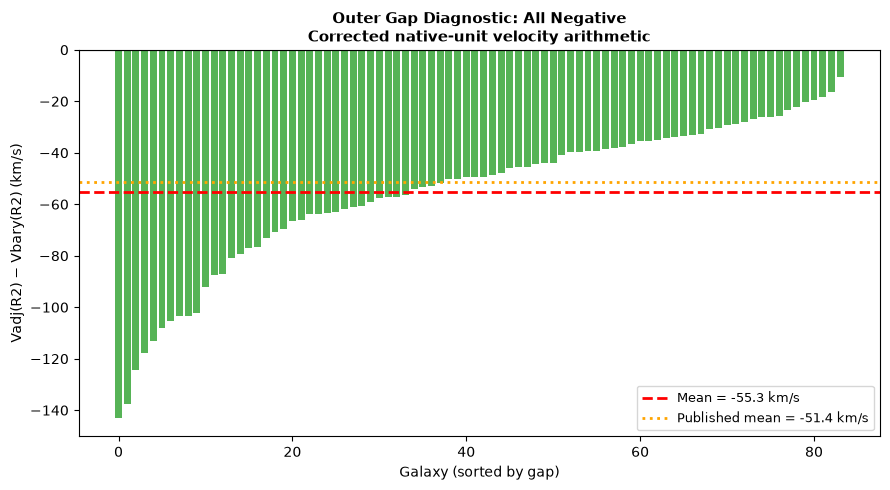


All 84/84 gaps remain negative after corrected-unit arithmetic.


In [4]:
# Plot outer gap distribution
fig, ax = plt.subplots(figsize=(9, 5))
gap_vals = sorted([g['gap'] for g in gaps])
colors = ['#2ca02c' if g < 0 else '#d62728' for g in gap_vals]
ax.bar(range(len(gap_vals)), gap_vals, color=colors, alpha=0.8)
ax.axhline(0, color='black', lw=1.5)
ax.axhline(mean_gap, color='red', ls='--', lw=2,
           label=f'Mean = {mean_gap:.1f} km/s')
ax.axhline(-51.4, color='orange', ls=':', lw=2,
           label='Published mean = -51.4 km/s')
ax.set_xlabel('Galaxy (sorted by gap)')
ax.set_ylabel('Vadj(R2) − Vbary(R2) (km/s)')
ax.set_title('Outer Gap Diagnostic: All Negative\n'
             'Corrected native-unit velocity arithmetic',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('p2_nb4_outer_gap.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\nAll {all_neg}/{len(gaps)} gaps remain negative after corrected-unit arithmetic.")
